In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv("Housing.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
X = df.drop("furnishingstatus", axis=1)
y = df["furnishingstatus"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_cols = X.select_dtypes(include="number").columns.tolist()
category_cols = X.select_dtypes(include="object").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), category_cols)
])

In [4]:
rf_classifier = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

rf_classifier.fit(X_train, y_train)

print("Random Forest Classifier trained successfully!")

Random Forest Classifier trained successfully!


In [5]:
class_pred = rf_classifier.predict(X_test)

accuracy = accuracy_score(y_test, class_pred)

print("Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, class_pred))

Accuracy: 0.5321

Classification Report:
                precision    recall  f1-score   support

     furnished       0.54      0.25      0.34        28
semi-furnished       0.50      0.76      0.60        45
   unfurnished       0.61      0.47      0.53        36

      accuracy                           0.53       109
     macro avg       0.55      0.49      0.49       109
  weighted avg       0.55      0.53      0.51       109



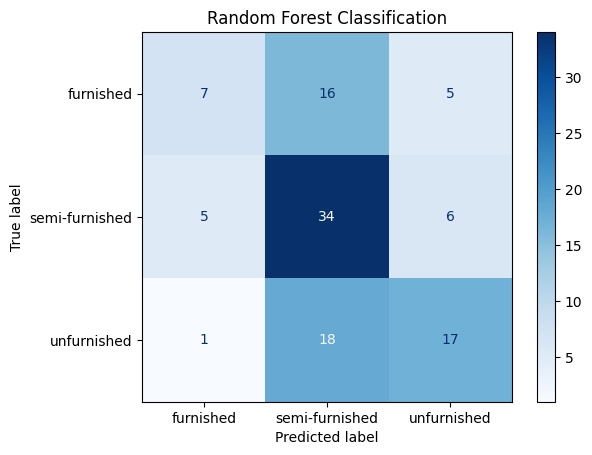

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    class_pred,
    cmap="Blues"
)

plt.title("Random Forest Classification")
plt.show()

In [7]:
os.makedirs("saved_models", exist_ok=True)

joblib.dump(
    rf_classifier,
    "saved_models/random_forest_classifier.joblib"
)

print("Random Forest Classifier saved!")

Random Forest Classifier saved!


In [8]:
X_reg = df.drop("price", axis=1)
y_reg = df["price"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

numeric_reg = X_reg.select_dtypes(include="number").columns.tolist()
category_reg = X_reg.select_dtypes(include="object").columns.tolist()

preprocessor_reg = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_reg),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), category_reg)
])

In [9]:
rf_regressor = Pipeline([
    ("preprocessing", preprocessor_reg),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

rf_regressor.fit(X_train_reg, y_train_reg)

print("Random Forest Regressor trained successfully!")

Random Forest Regressor trained successfully!


In [10]:
reg_pred = rf_regressor.predict(X_test_reg)

mae = mean_absolute_error(y_test_reg, reg_pred)
mse = mean_squared_error(y_test_reg, reg_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, reg_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

MAE: 1079526.22
MSE: 2121042051848.08
RMSE: 1456379.78
R² Score: 0.5804


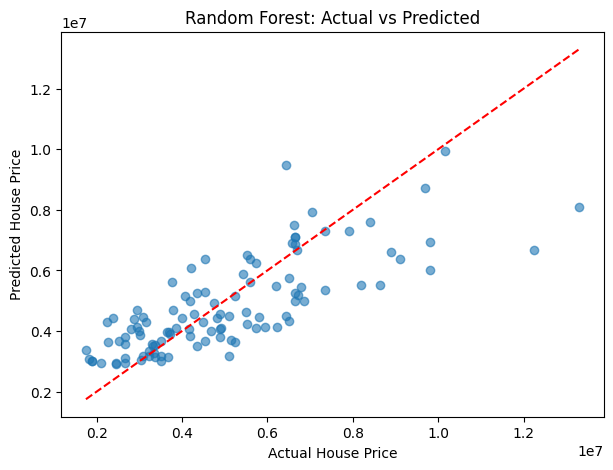

In [11]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test_reg, reg_pred, alpha=0.6)

plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    "r--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

In [12]:
joblib.dump(
    rf_regressor,
    "saved_models/random_forest_regressor.joblib"
)

print("Random Forest Regressor saved!")

Random Forest Regressor saved!
